# Lab 4.2 — Reasoning Prompts with LangChain: Chain-of-Thought, Self-Consistency and Self-Feedback
**Course:** AI Agents · **Unit:** UC4 — AI Agents
 · **Platform:** Google Colab (T4 GPU recommended)

In **Lab 2.6** you measured *why* explicit reasoning helps: chain-of-thought (CoT) gives the model more computation, and sampling several reasoning paths and voting (self-consistency) makes answers more reliable. In **Lab 4.1** you learned to build prompts as LangChain components (templates, few-shot examples, `prompt | llm | parser`).

This lab joins the two. We turn reasoning techniques into **reusable components that an agent's code can call**, and we add a new family of techniques: **self-feedback**, where the model critiques and improves its own output.

### Learning objectives
1. Implement zero-shot CoT with an **answer contract** and a parser, in one stage and in two stages (reason → extract).
2. Write **few-shot CoT** examples for a new task and show when worked reasoning beats answer-only examples.
3. Build **self-consistency** as a reusable function and use the **agreement** between samples as a confidence signal to decide when an agent should abstain.
4. Implement a **self-refine** loop (generate → feedback → refine), compare **intrinsic** (LLM) feedback with **external** (code) feedback, and test whether a small model can correct its own reasoning.

### Lab structure
| Part | Topic | What you do |
|---|---|---|
| 0 | Setup, problem set and helpers | Run |
| 1 | Zero-shot CoT as a LangChain component (one and two stages) | Run |
| 2 | Few-shot CoT | Run, then **Exercise 1** |
| 3 | Self-consistency and confidence | Run, then **Exercise 2** |
| 4 | Self-feedback: self-refine and self-correction | Run, then **Exercise 3** |
| 5 | Questions | Answer |

### Running this notebook in Google Colab
1. **File → Upload notebook**, then **Runtime → Change runtime type → T4 GPU → Save**.
2. Run the cells **in order**. Part 0 installs Ollama and downloads the model (≈ 2 minutes).
3. Some cells generate many answers (Part 3 makes 60 calls). On a T4 each of those cells takes 1–3 minutes.

> **On your own laptop:** install Ollama from <https://ollama.com/download>, skip cell 0.1 and run the rest unchanged.

## Part 0 — Setup
Same setup as Lab 3.3: Ollama serves `llama3.2:3b` locally and LangChain talks to it with `ChatOllama`. We create **two** model objects:

| Object | Settings | Used for |
|---|---|---|
| `llm` | `temperature=0` | evaluation, critiques and rewrites — reproducible |
| `llm_sample` | `temperature=0.7`, `top_p=0.95` | self-consistency: we *want* different reasoning paths (Lab 2.5) |

In [1]:
#%% 0.1 Install Ollama and start the server (once per Colab session, ~1 minute)
import os, subprocess, time, urllib.request

!sudo apt-get -qq update > /dev/null 2>&1 && sudo apt-get -qq install -y zstd pciutils > /dev/null 2>&1
!curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1

os.environ["OLLAMA_HOST"] = "127.0.0.1:11434"
os.environ["OLLAMA_NUM_PARALLEL"] = "4"      # answer several requests at once (used by .batch())
ollama_log = open("ollama.log", "w")
ollama_proc = subprocess.Popen(["ollama", "serve"], stdout=ollama_log, stderr=subprocess.STDOUT)

def wait_for_ollama(timeout=60):
    # Poll the local API until the server answers, or give up after `timeout` seconds.
    for _ in range(timeout):
        try:
            urllib.request.urlopen("http://127.0.0.1:11434", timeout=2)
            return True
        except Exception:
            time.sleep(1)
    return False

print("✅ Ollama server is running" if wait_for_ollama() else "❌ Server did not start:\n" + open("ollama.log").read()[-2000:])

✅ Ollama server is running


In [2]:
#%% 0.2 Download the model and install LangChain
MODEL = "llama3.2:3b"        # faster alternative: "qwen2.5:1.5b" (weaker reasoning, so expect lower accuracy)
!ollama pull {MODEL} > /dev/null 2>&1
!ollama list
%pip install -q -U langchain-core langchain-ollama

NAME           ID              SIZE      MODIFIED               
llama3.2:3b    a80c4f17acd5    2.0 GB    Less than a second ago    


In [3]:
#%% 0.3 Imports and models
import re, textwrap, time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, FewShotChatMessagePromptTemplate
from langchain_core.runnables import RunnableLambda, RunnablePassthrough
from langchain_ollama import ChatOllama

llm = ChatOllama(model=MODEL, temperature=0, num_predict=512, num_ctx=4096)
llm_sample = ChatOllama(model=MODEL, temperature=0.7, top_p=0.95, num_predict=512, num_ctx=4096)
print(llm.invoke("Say 'ready' and nothing else.").content)

ready


### 0.4 Problem set and helpers
Twelve short word problems (2–4 steps each) with integer answers. Two helpers are used in the whole lab:
- `extract_answer(text)` — takes the number after the **last** `Answer:` line; if there is none, the last number in the text;
- `run_math(chain, name)` — runs a chain on all problems with one `.batch()` call and reports **accuracy**, **mean output tokens** (cost) and **time**.

The chains we evaluate end in `llm` (not in a string parser), so `run_math` can read the token counts from each `AIMessage`.

In [4]:
#%% 0.4 Problems and evaluation helpers
PROBLEMS = [
    ("A school has 3 buses with 42 seats each, all full, and a fourth bus with 17 students. How many students are travelling?", 143),
    ("If 5 machines make 5 widgets in 5 minutes, how many minutes do 100 machines need to make 100 widgets?", 5),
    ("A lab runs 6 experiments per day from Monday to Friday and 2 per day on Saturday and Sunday. How many experiments does it run in 3 weeks?", 102),
    ("A train leaves at 9:40 and arrives at 13:15. How many minutes does the trip take?", 215),
    ("There are 120 students. 25% study physics, and one third of the rest study chemistry. How many study neither?", 60),
    ("A rectangle has a perimeter of 54 cm and its length is twice its width. What is its area in square cm?", 162),
    ("Pedro is 3 times as old as his daughter. In 12 years he will be twice as old as her. How old is Pedro now?", 36),
    ("Pencils are sold in packs of 12 for $3. A teacher needs 100 pencils and can only buy whole packs. How many dollars does she spend?", 27),
    ("A 500-liter tank is 40% full. A pump adds 15 liters per minute. How many minutes until the tank is full?", 20),
    ("Luis reads 18 pages on the first day, and each day he reads 4 pages more than the day before. How many pages has he read after 5 days?", 130),
    ("A farm has chickens and cows: 30 heads and 74 legs in total. How many cows are there?", 7),
    ("A phone costs $480. It is discounted 15%, then a 12% tax is added to the discounted price. What is the final price, rounded to the nearest dollar?", 457),
]

def extract_answer(text):
    # Number after the last 'Answer:' (or the last number in the text); None if there is no number.
    hits = re.findall(r"answer[^0-9\-\n]*(-?\d[\d,]*(?:\.\d+)?)", text, flags=re.IGNORECASE)
    if not hits:
        hits = re.findall(r"-?\d[\d,]*(?:\.\d+)?", text)
    if not hits:
        return None
    try:
        value = float(hits[-1].replace(",", ""))
        return int(value) if value.is_integer() else value
    except ValueError:
        return None

def is_correct(pred, gold):
    return pred is not None and abs(pred - gold) < 1e-6

def as_text(out):
    return out.content if hasattr(out, "content") else str(out)

def run_math(chain, name, problems=PROBLEMS, inputs=None):
    # Run `chain` on every problem; return a DataFrame and print accuracy, mean output tokens and time.
    inputs = inputs or [{"question": q} for q, _ in problems]
    t0 = time.time()
    outs = chain.batch(inputs, config={"max_concurrency": 4})
    elapsed = time.time() - t0
    rows = []
    for (q, gold), out in zip(problems, outs):
        text = as_text(out)
        usage = getattr(out, "usage_metadata", None) or {}
        pred = extract_answer(text)
        rows.append({"question": textwrap.shorten(q, 45), "gold": gold, "pred": pred,
                     "correct": is_correct(pred, gold), "output_tokens": usage.get("output_tokens"), "text": text})
    df = pd.DataFrame(rows)
    print(f"{name:30s} accuracy = {df.correct.mean():4.0%} | mean output tokens = {df.output_tokens.mean():5.0f}"
          f" | time = {elapsed:5.1f} s")
    return df

print(extract_answer("3 x 42 = 126\n126 + 17 = 143\nAnswer: 143"), extract_answer("The price is $456.96, so about $457."))

143 457


---
## Part 1 — Zero-shot CoT as a LangChain component

### 1.1 The answer contract
Free-form reasoning is useful for the model but a problem for the **code** that receives it: where is the answer? A reasoning prompt for an agent therefore has two parts:
1. **permission to think**: "think step by step, write each calculation";
2. an **answer contract**: "finish with a last line `Answer: <number>`", plus a parser that enforces it.

With the parser at the end of the chain, `cot_solver.invoke(...)` returns a **number**, so the rest of the agent never has to read the reasoning.

In [5]:
#%% 1.1 Direct vs zero-shot CoT, with an answer parser
DIRECT_SYSTEM = "You solve math word problems. Reply with the final number only, without units or explanation."
COT_SYSTEM = ("You solve math word problems. Think step by step and write each calculation on its own line. "
              "Finish with a last line of the form 'Answer: <number>'.")

direct_prompt = ChatPromptTemplate.from_messages([("system", DIRECT_SYSTEM), ("human", "{question}")])
cot_prompt = ChatPromptTemplate.from_messages([("system", COT_SYSTEM), ("human", "{question}")])

answer_parser = RunnableLambda(lambda msg: extract_answer(msg.content))    # AIMessage → number
cot_solver = cot_prompt | llm | answer_parser

q, gold = PROBLEMS[6]
print("Question:", q)
print("\n━━━ What the model writes ━━━\n" + (cot_prompt | llm).invoke({"question": q}).content)
print("\n━━━ What the agent's code receives ━━━\n", repr(cot_solver.invoke({"question": q})), "| gold:", gold)

Question: Pedro is 3 times as old as his daughter. In 12 years he will be twice as old as her. How old is Pedro now?

━━━ What the model writes ━━━
Let's denote Pedro's current age as P and his daughter's current age as D.

Since Pedro is 3 times as old as his daughter, we can write the equation:
P = 3D

In 12 years, Pedro's age will be P + 12 and his daughter's age will be D + 12. According to the problem, in 12 years, Pedro will be twice as old as his daughter, so we can write the equation:
P + 12 = 2(D + 12)

Now, let's simplify the equation:
P + 12 = 2D + 24

Subtract 12 from both sides:
P = 2D + 12

Now we have two equations:
P = 3D
P = 2D + 12

Since both equations are equal to P, we can set them equal to each other:
3D = 2D + 12

Subtract 2D from both sides:
D = 12

Now that we know D, we can find P:
P = 3D
P = 3(12)
P = 36

Answer: 36

━━━ What the agent's code receives ━━━
 36 | gold: 36


In [6]:
#%% 1.2 Evaluate both prompts on the problem set
direct_df = run_math(direct_prompt | llm, "direct answer")
cot_df = run_math(cot_prompt | llm, "zero-shot CoT (one stage)")
display(pd.DataFrame({"question": cot_df.question, "gold": cot_df.gold,
                      "direct": direct_df.pred, "CoT": cot_df.pred}))

direct answer                  accuracy =   8% | mean output tokens =     2 | time =  25.3 s
zero-shot CoT (one stage)      accuracy = 100% | mean output tokens =   142 | time =  10.3 s


,question,gold,direct,CoT
0,A school has 3 buses with 42 seats [...],143,129,143
1,If 5 machines make 5 widgets in 5 [...],5,200,5
2,A lab runs 6 experiments per day from [...],102,294,102
3,A train leaves at 9:40 and arrives at [...],215,205,215
4,There are 120 students. 25% study [...],60,90,60
5,A rectangle has a perimeter of 54 cm [...],162,162,162
6,Pedro is 3 times as old as his [...],36,45,36
7,Pencils are sold in packs of 12 for $3. [...],27,9,27
8,A 500-liter tank is 40% full. A pump [...],20,1200,20
9,"Luis reads 18 pages on the first day, [...]",130,76,130


### 1.3 Two-stage zero-shot CoT
The original zero-shot CoT paper (Kojima et al., 2022) used **two calls**:
1. **reasoning**: the question followed by *"Let's think step by step."* — no format constraint at all;
2. **answer extraction**: the question + the reasoning + *"Therefore, the answer (a number only) is"*.

Separating the two lets the model reason freely and makes the final answer easy to parse, at the cost of a second call. Below, `RunnablePassthrough.assign(reasoning=...)` runs the first chain and **adds** its output to the input dictionary, so the second prompt can use both `{question}` and `{reasoning}`. This is our first *sequential chain* — the topic of the next lab.

In [7]:
#%% 1.3 Two-stage CoT: reason, then extract
reason_prompt = ChatPromptTemplate.from_messages([("human", "{question}\n\nLet's think step by step.")])
extract_prompt = ChatPromptTemplate.from_messages([
    ("human", "{question}\n\nReasoning:\n{reasoning}\n\nTherefore, the final answer (a number only) is:")])

two_stage = (RunnablePassthrough.assign(reasoning=reason_prompt | llm | StrOutputParser())
             | extract_prompt | llm)

out = (RunnablePassthrough.assign(reasoning=reason_prompt | llm | StrOutputParser())).invoke({"question": PROBLEMS[4][0]})
print("Keys after stage 1:", list(out.keys()))
print(textwrap.shorten(out["reasoning"], 400))

two_df = run_math(two_stage, "zero-shot CoT (two stages)")
print("(output tokens counted for stage 2 only)")

Keys after stage 1: ['question', 'reasoning']
To find the number of students who study neither physics nor chemistry, we need to follow these steps: 1. Calculate the number of students who study physics: 25% of 120 students study physics. To find 25% of 120, multiply 120 by 0.25: 120 x 0.25 = 30 So, 30 students study physics. 2. Calculate the number of students who do not study physics: Since 30 students study physics, subtract 30 from [...]
zero-shot CoT (two stages)     accuracy =  83% | mean output tokens =    10 | time =  16.6 s
(output tokens counted for stage 2 only)


👉 **Compare** the three rows (direct, one stage, two stages). Look at the problems where CoT fails: is the **reasoning** wrong, or was the answer **extracted** badly? That difference matters when you debug an agent.

---
## Part 2 — Few-shot CoT
In Lab 3.3 the few-shot examples showed only the **answer** (a label). For reasoning tasks the examples should also show **how** to get there (Wei et al., 2022). We reuse `FewShotChatMessagePromptTemplate` and write every example twice — answer-only and with worked steps — so we can measure what the *reasoning* in the examples adds.

In [8]:
#%% 2.1 Few-shot examples, with and without reasoning
EXAMPLES = [
    {"question": "A library has 3 shelves with 28 books each. It lends out 19 books. How many books remain?",
     "steps": "3 shelves × 28 books = 84 books.\n84 − 19 lent = 65 books remain.", "answer": "65"},
    {"question": "A cyclist rides at 18 km/h for 2.5 hours and then at 12 km/h for 1.5 hours. How many km does she ride?",
     "steps": "First part: 18 × 2.5 = 45 km.\nSecond part: 12 × 1.5 = 18 km.\nTotal: 45 + 18 = 63 km.", "answer": "63"},
    {"question": "A class has 36 students. Two thirds passed the exam, and half of those who passed got an A. How many got an A?",
     "steps": "Passed: 36 × 2/3 = 24 students.\nGot an A: 24 / 2 = 12 students.", "answer": "12"},
    {"question": "Sara has twice as many stickers as Tom. Together they have 54. How many stickers does Sara have?",
     "steps": "Let Tom have x. Sara has 2x.\nx + 2x = 3x = 54, so x = 18.\nSara has 2 × 18 = 36.", "answer": "36"},
]
cot_examples = [{"question": e["question"], "solution": e["steps"] + "\nAnswer: " + e["answer"]} for e in EXAMPLES]
answer_only_examples = [{"question": e["question"], "solution": e["answer"]} for e in EXAMPLES]

example_prompt = ChatPromptTemplate.from_messages([("human", "{question}"), ("ai", "{solution}")])

def make_few_shot(system, examples):
    # System message + examples as human/ai turns + the real question.
    few_shot = FewShotChatMessagePromptTemplate(example_prompt=example_prompt, examples=examples)
    return ChatPromptTemplate.from_messages([("system", system), few_shot, ("human", "{question}")])

few_cot_prompt = make_few_shot(COT_SYSTEM, cot_examples)
few_ans_prompt = make_few_shot(DIRECT_SYSTEM, answer_only_examples)
for m in few_cot_prompt.invoke({"question": "(the real question goes here)"}).to_messages()[:3]:
    m.pretty_print()

================================ System Message ================================

You solve math word problems. Think step by step and write each calculation on its own line. Finish with a last line of the form 'Answer: <number>'.
================================ Human Message =================================

A library has 3 shelves with 28 books each. It lends out 19 books. How many books remain?
================================== Ai Message ==================================

3 shelves × 28 books = 84 books.
84 − 19 lent = 65 books remain.
Answer: 65


In [9]:
#%% 2.2 Compare the four prompting styles
few_ans_df = run_math(few_ans_prompt | llm, "few-shot, answer only")
few_cot_df = run_math(few_cot_prompt | llm, "few-shot CoT")

styles = {"direct": direct_df, "zero-shot CoT": cot_df, "few-shot answer only": few_ans_df, "few-shot CoT": few_cot_df}
summary = pd.DataFrame({name: {"accuracy": df.correct.mean(), "mean output tokens": df.output_tokens.mean()}
                        for name, df in styles.items()}).T
display(summary.round(2))

few-shot, answer only          accuracy =   0% | mean output tokens =     2 | time =   1.0 s
few-shot CoT                   accuracy =  83% | mean output tokens =    74 | time =   7.1 s


,accuracy,mean output tokens
direct,0.08,2.08
zero-shot CoT,1.00,141.75
few-shot answer only,0.00,2.00
few-shot CoT,0.83,74.17


> With 12 problems, one problem is worth ≈ 8 percentage points, and math problems are a task where *zero-shot* CoT already works well for this model (Lab 2.6). Few-shot CoT shows its value most clearly on tasks whose **procedure** is not obvious to the model — like the one in Exercise 1.

### ✏️ Exercise 1 — Few-shot CoT for a symbolic task
**Last-letter concatenation** is a classic test from the CoT papers: *"Take the last letter of each word in 'Maria Jose Carlos' and concatenate them"* → `aes`. It is easy for people but hard for LLMs, because models see **tokens**, not letters.

1. Write `DIRECT_L` (answer only) and `COT_L` (step by step) system prompts. Both must end with the contract `Answer: <letters>`.
2. Write **3 few-shot CoT examples** whose reasoning spells out each word and its last letter (e.g. `Maria → a`). Use names that are **not** in `WORD_LISTS`.
3. Evaluate direct, zero-shot CoT and few-shot CoT with `run_letters` and compare them in a table.
4. Look at one wrong answer per style: what kind of error is it?

In [ ]:
#%% Exercise 1 — the task (run this cell)
WORD_LISTS = ["Maria Jose Carlos", "Lucia Andres Paola Diego", "Sofia Mateo Gabriel",
              "Valentina Sebastian Camila Tomas", "Isabel Ricardo Elena", "Daniela Martin Fernanda Hugo",
              "Carmen Pablo Ines", "Alejandro Rosa Felipe Nora"]
LETTER_TASK = [(f"Take the last letter of each word in \"{w}\" and concatenate them.",
                "".join(word[-1] for word in w.split()).lower()) for w in WORD_LISTS]

def extract_letters(text):
    # Letters after the last 'Answer:'; otherwise the last word of the text.
    hits = re.findall(r"answer\s*[:=]\s*[\"'*]*([a-zA-Z]+)", text, flags=re.IGNORECASE)
    if hits:
        return hits[-1].lower()
    words = text.strip().split()
    return words[-1].strip("\"'.*").lower() if words else ""

def run_letters(chain, name):
    outs = chain.batch([{"question": q} for q, _ in LETTER_TASK], config={"max_concurrency": 4})
    rows = [{"words": w, "gold": gold, "pred": extract_letters(as_text(o)), "text": as_text(o)}
            for w, (_, gold), o in zip(WORD_LISTS, LETTER_TASK, outs)]
    df = pd.DataFrame(rows)
    df["correct"] = df.pred == df.gold
    print(f"{name:22s} accuracy = {df.correct.mean():4.0%}")
    return df

pd.DataFrame(LETTER_TASK, columns=["question", "gold"])

In [ ]:
#%% Exercise 1 — your solution
DIRECT_L = ""     # TODO: answer only, ending with the contract "Answer: <letters>"
COT_L = ""        # TODO: step by step, ending with the contract "Answer: <letters>"
LETTER_EXAMPLES = [
    # {"question": "Take the last letter of each word in \"...\" and concatenate them.",
    #  "solution": "...\nAnswer: ..."},
]

# direct_l_df  = run_letters(ChatPromptTemplate.from_messages([("system", DIRECT_L), ("human", "{question}")]) | llm, "direct")
# cot_l_df     = run_letters(ChatPromptTemplate.from_messages([("system", COT_L), ("human", "{question}")]) | llm, "zero-shot CoT")
# few_cot_l_df = run_letters(make_few_shot(COT_L, LETTER_EXAMPLES) | llm, "few-shot CoT")

---
## Part 3 — Self-consistency as a component, and confidence

Self-consistency (Wang et al., 2023): sample `n` reasoning paths at a moderate temperature, extract each answer, return the **majority**. In Lab 3.3 you saw that it improves accuracy. Here we focus on two engineering questions:
1. how to package it as a **reusable function** that works with any chain;
2. how to use the **agreement** between samples (`votes for the winner / n`) as a **confidence score** — something an agent needs in order to decide whether to act, or to ask a human.

In [10]:
#%% 3.1 A reusable self-consistency function
def self_consistency(chain, inputs, n=5, extract=extract_answer):
    # Sample n answers from `chain` (which must use a temperature > 0) and return the majority vote.
    outs = chain.batch([inputs] * n, config={"max_concurrency": 4})
    texts = [as_text(o) for o in outs]
    answers = [extract(t) for t in texts]
    tokens = sum((getattr(o, "usage_metadata", None) or {}).get("output_tokens", 0) for o in outs)
    votes = Counter(a for a in answers if a is not None)
    if not votes:
        return {"answer": None, "agreement": 0.0, "answers": answers, "tokens": tokens}
    answer, count = votes.most_common(1)[0]
    return {"answer": answer, "agreement": count / n, "answers": answers, "tokens": tokens}

sc_chain = cot_prompt | llm_sample            # same prompt as Part 1, but sampled at T = 0.7

q, gold = PROBLEMS[11]
res = self_consistency(sc_chain, {"question": q}, n=5)
print("Question:", q)
print("Sampled answers:", res["answers"], "→ majority:", res["answer"], f"| agreement = {res['agreement']:.0%} | gold = {gold}")

Question: A phone costs $480. It is discounted 15%, then a 12% tax is added to the discounted price. What is the final price, rounded to the nearest dollar?
Sampled answers: [457, 457, 457, 457, 457] → majority: 457 | agreement = 100% | gold = 457


### 3.2 Accuracy and agreement on the whole problem set
We sample `N_MAX = 5` paths per problem **once** (60 calls) and then compute the vote for `n = 1, 3, 5` from the first `n` samples, so we don't pay for the same samples three times. The baseline is greedy CoT (`temperature = 0`) from Part 1.

done in 80 s


,accuracy,output tokens per problem
n samples,,
1,0.83,146.5
3,0.83,439.5
5,1.00,732.5


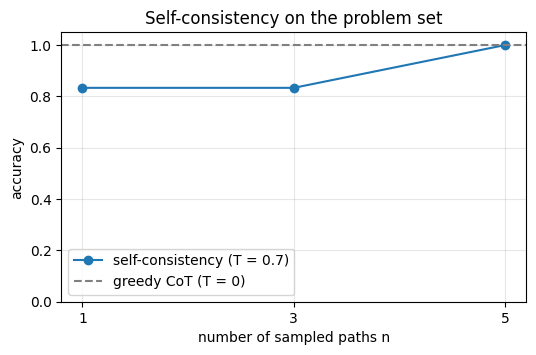

In [11]:
#%% 3.2 Sample 5 paths per problem (~1–3 minutes)
N_MAX = 5
sc_runs = []
t0 = time.time()
for q, gold in PROBLEMS:
    r = self_consistency(sc_chain, {"question": q}, n=N_MAX)
    sc_runs.append({"question": textwrap.shorten(q, 45), "gold": gold, **r})
print(f"done in {time.time() - t0:.0f} s")

def vote(answers):
    votes = Counter(a for a in answers if a is not None)
    return votes.most_common(1)[0] if votes else (None, 0)

rows = []
for n in (1, 3, 5):
    correct = [is_correct(vote(r["answers"][:n])[0], r["gold"]) for r in sc_runs]
    rows.append({"n samples": n, "accuracy": sum(correct) / len(correct),
                 "output tokens per problem": sum(r["tokens"] for r in sc_runs) / len(sc_runs) * n / N_MAX})
sc_table = pd.DataFrame(rows).set_index("n samples")
display(sc_table.round(2))

plt.figure(figsize=(6, 3.5))
plt.plot(sc_table.index, sc_table.accuracy, marker="o", label="self-consistency (T = 0.7)")
plt.axhline(cot_df.correct.mean(), linestyle="--", color="gray", label="greedy CoT (T = 0)")
plt.xlabel("number of sampled paths n"); plt.ylabel("accuracy"); plt.ylim(0, 1.05)
plt.xticks([1, 3, 5]); plt.grid(alpha=0.3); plt.legend(); plt.title("Self-consistency on the problem set"); plt.show()

In [12]:
#%% 3.3 Is agreement a good confidence signal?
sc_df = pd.DataFrame([{"question": r["question"], "gold": r["gold"], "answers": r["answers"],
                       "majority": vote(r["answers"])[0], "agreement": vote(r["answers"])[1] / N_MAX}
                      for r in sc_runs])
sc_df["correct"] = [is_correct(m, g) for m, g in zip(sc_df.majority, sc_df.gold)]
display(sc_df.sort_values("agreement", ascending=False))
display(sc_df.groupby("agreement").correct.agg(["count", "mean"]).rename(columns={"mean": "accuracy"}))

,question,gold,answers,majority,agreement,correct
0,A school has 3 buses with 42 seats [...],143,"[143, 143, 143, 143, 143]",143,1.0,True
2,A lab runs 6 experiments per day from [...],102,"[102, 102, 102, 102, 102]",102,1.0,True
8,A 500-liter tank is 40% full. A pump [...],20,"[20, 20, 20, 20, 20]",20,1.0,True
6,Pedro is 3 times as old as his [...],36,"[36, 36, 36, 36, 36]",36,1.0,True
10,A farm has chickens and cows: 30 heads [...],7,"[7, 7, 7, 7, 7]",7,1.0,True
3,A train leaves at 9:40 and arrives at [...],215,"[215, 215, 275, 215, 215]",215,0.8,True
11,A phone costs $480. It is discounted [...],457,"[458, 457, 457, 457, 457]",457,0.8,True
5,A rectangle has a perimeter of 54 cm [...],162,"[162, 162, 162, 9, 162]",162,0.8,True
7,Pencils are sold in packs of 12 for $3. [...],27,"[27, 27, 27, 27, 3]",27,0.8,True
4,There are 120 students. 25% study [...],60,"[30, 60, 30, 60, 60]",60,0.6,True


,count,accuracy
agreement,,
0.4,1,1.0
0.6,2,1.0
0.8,4,1.0
1.0,5,1.0


👉 **Read the last table.** When all 5 paths agree, how often is the majority right? And when only 2 or 3 agree? If high agreement means "probably right" and low agreement means "risky", the agent can use it to decide **when to answer and when to ask for help**.

Notice also the structure of what we built: `n` **independent** calls of the same chain, then a **merge** step (the vote). In the next lab this becomes a *parallel chain*.

### ✏️ Exercise 2 — Abstention and cost
**(a) Selective answering.** An agent answers only when `agreement ≥ threshold`, and otherwise says *"I'm not sure, I'll ask a human"*. For thresholds `0.4, 0.6, 0.8, 1.0` compute, from `sc_df`:
- **coverage** = fraction of problems the agent answers,
- **selective accuracy** = accuracy on the answered problems.

Show a table and plot both against the threshold. Which threshold would you choose for an agent that grades student work? And for a homework helper?

**(b) Cost.** Using `sc_table` and the few-shot CoT result of Part 2, write a short table: accuracy and output tokens per problem for greedy CoT, few-shot CoT and self-consistency with n = 5. Is self-consistency worth 5× the tokens here?

**(c) Why temperature > 0?** Run `self_consistency` with a chain that uses `llm` (temperature 0) on 3 problems. What agreement do you get, and why does that make the vote useless?

In [ ]:
#%% Exercise 2 — your solution
# (a)
# rows = []
# for threshold in (0.4, 0.6, 0.8, 1.0):
#     answered = sc_df[sc_df.agreement >= threshold]
#     rows.append({"threshold": threshold, "coverage": ..., "selective accuracy": ...})
# ...

# (b)
# ...

# (c)
# for q, gold in PROBLEMS[:3]:
#     r = self_consistency(cot_prompt | llm, {"question": q}, n=3)
#     ...

---
## Part 4 — Self-feedback

**Self-Refine** (Madaan et al., 2023) uses **one model in three roles**, each with its own prompt:

```
          ┌──────────── refine (draft + feedback → new draft) ◄───────┐
          ▼                                                           │
 generate ──► draft ──► feedback (critique against the requirements) ─┤
                                                                      └─► STOP when the feedback says "done"
```

Two kinds of feedback:
- **intrinsic** — the LLM critiques its own draft;
- **external** — something outside the model gives the feedback: a program, a tool, a test suite, a human.

To know whether the loop really improves the output, we need a task where the quality can be **checked objectively**. We use a short announcement with six requirements that a Python function can verify. The model never sees the checker: it is our **ground truth**.

In [13]:
#%% 4.1 The task and an objective checker
TOPIC = "the next AI Agents lab, about chain-of-thought and self-consistency"
CONSTRAINTS = [
    "Use at most 60 words.",
    "Mention the date November 21.",
    "Mention the word Ollama.",
    "Do not use exclamation marks.",
    "Include a line that starts with 'Deadline:'.",
    "End with a question.",
]
REQUIREMENTS = "\n".join(f"- {c}" for c in CONSTRAINTS)

def check(text):
    # Ground truth: which constraints does `text` satisfy? Returns (dict, word count).
    t = text.strip()
    words = len(re.findall(r"[\w'’-]+", t))
    results = {
        CONSTRAINTS[0]: words <= 60,
        CONSTRAINTS[1]: "november 21" in t.lower(),
        CONSTRAINTS[2]: "ollama" in t.lower(),
        CONSTRAINTS[3]: "!" not in t,
        CONSTRAINTS[4]: any(line.strip().lstrip("*-#> ").lower().startswith("deadline") for line in t.splitlines()),
        CONSTRAINTS[5]: t.rstrip("*_ \n").endswith("?"),
    }
    return results, words

example = "New lab on November 21!\nDeadline: Sunday.\nWe use Ollama. Ready?"
results, words = check(example)
print(f"{words} words")
for c, ok in results.items():
    print("✅" if ok else "❌", c)

11 words
✅ Use at most 60 words.
✅ Mention the date November 21.
✅ Mention the word Ollama.
❌ Do not use exclamation marks.
✅ Include a line that starts with 'Deadline:'.
✅ End with a question.


In [14]:
#%% 4.2 Three prompts: generate, feedback, refine
gen_prompt = ChatPromptTemplate.from_messages([
    ("system", "You write short announcements for university students."),
    ("human", "Write an announcement about {topic}.\nRequirements:\n{requirements}\nReturn only the announcement."),
])
feedback_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are a meticulous editor."),
    ("human", "Requirements:\n{requirements}\n\nDraft:\n<<<\n{draft}\n>>>\n\n"
              "Check the draft against EACH requirement, one per line, in the form "
              "'<requirement> → SATISFIED' or '<requirement> → NOT SATISFIED: <reason>'. "
              "Count the words carefully. If every requirement is satisfied, write STOP on the last line."),
])
refine_prompt = ChatPromptTemplate.from_messages([
    ("system", "You write short announcements for university students."),
    ("human", "Requirements:\n{requirements}\n\nPrevious draft:\n<<<\n{draft}\n>>>\n\nFeedback:\n{feedback}\n\n"
              "Rewrite the draft so that it satisfies every requirement. Keep what already works. "
              "Return only the new announcement."),
])
gen_chain = gen_prompt | llm | StrOutputParser()
feedback_chain = feedback_prompt | llm | StrOutputParser()
refine_chain = refine_prompt | llm | StrOutputParser()

def llm_feedback(draft):
    return feedback_chain.invoke({"requirements": REQUIREMENTS, "draft": draft})

def llm_says_done(feedback):
    return "STOP" in feedback and "NOT SATISFIED" not in feedback.upper()

In [15]:
#%% 4.3 The self-refine loop
def self_refine(feedback_fn, done_fn, max_iters=3, verbose=True):
    # generate → (feedback → refine)* until done_fn(feedback) or max_iters; the checker scores every draft.
    draft = gen_chain.invoke({"topic": TOPIC, "requirements": REQUIREMENTS})
    history = []
    for it in range(max_iters + 1):
        results, words = check(draft)
        feedback = feedback_fn(draft) if it < max_iters else ""
        done = done_fn(feedback) if feedback else None
        history.append({"iteration": it, "words": words, "score": sum(results.values()),
                        "failed (checker)": [c for c, ok in results.items() if not ok],
                        "feedback says done": done, "draft": draft, "feedback": feedback})
        if verbose:
            print(f"━━━ iteration {it} | checker score {sum(results.values())}/{len(results)} | {words} words ━━━")
            print(draft)
            if feedback:
                print("\n— feedback —\n" + feedback + "\n")
        if it == max_iters or done:
            break
        draft = refine_chain.invoke({"requirements": REQUIREMENTS, "draft": draft, "feedback": feedback})
    return pd.DataFrame(history)

intrinsic = self_refine(llm_feedback, llm_says_done)
display(intrinsic[["iteration", "words", "score", "failed (checker)", "feedback says done"]])

━━━ iteration 0 | checker score 5/6 | 57 words ━━━
The next AI Agents lab will focus on chain-of-thought and self-consistency. We will explore how agents can maintain consistency in their decision-making processes. Inspired by Ollama's approach, we will delve into the importance of self-consistency in AI development. Deadline: submit your research proposals by November 21. Can you design an agent that consistently adapts to changing environments?

— feedback —
requirement → SATISFIED: The draft is within the 60-word limit.
requirement → SATISFIED: The draft mentions the date November 21.
requirement → SATISFIED: The draft mentions the word Ollama.
requirement → NOT SATISFIED: The draft uses exclamation marks.
requirement → SATISFIED: The draft includes a line that starts with 'Deadline:'.
requirement → NOT SATISFIED: The draft does not end with a question.

STOP

━━━ iteration 1 | checker score 5/6 | 57 words ━━━
The next AI Agents lab will focus on chain-of-thought and self-consistenc

,iteration,words,score,failed (checker),feedback says done
0,0,57,5,[Include a line that starts with 'Deadline:'.],False
1,1,57,5,[Include a line that starts with 'Deadline:'.],False
2,2,57,5,[Include a line that starts with 'Deadline:'.],False
3,3,57,5,[Include a line that starts with 'Deadline:'.],None


👉 **Compare the model's opinion with the checker.** Did the model say STOP while the checker still found failures (a *false STOP*)? Did it report problems that were not there? Which requirements were hardest to fix — and why is counting words especially hard for an LLM?

### 4.4 Can the model correct its own reasoning?
Self-refine works best when the feedback is **easy to verify**. What about math reasoning, where checking is as hard as solving? Below, the model reviews its own CoT answers from Part 1 (intrinsic feedback only: it is **not** told which answers are wrong). We count four outcomes: right → right, right → wrong, wrong → right, wrong → wrong.

In [ ]:
#%% 4.4 Intrinsic self-correction on the math problems
self_check_prompt = ChatPromptTemplate.from_messages([
    ("system", COT_SYSTEM),
    ("human", "{question}"),
    ("ai", "{previous}"),
    ("human", "Review your previous answer step by step and check every calculation. If you find a mistake, "
              "fix it. Finish with a last line of the form 'Answer: <number>'."),
])
inputs = [{"question": q, "previous": text} for (q, _), text in zip(PROBLEMS, cot_df.text)]
review_df = run_math(self_check_prompt | llm, "CoT + self-review", inputs=inputs)

transitions = pd.crosstab(cot_df.correct.map({True: "right", False: "wrong"}).rename("before review"),
                          review_df.correct.map({True: "right", False: "wrong"}).rename("after review"))
display(transitions)

> Huang et al. (2024) found that, **without external feedback**, LLMs often fail to improve their reasoning by self-correction, and sometimes turn right answers into wrong ones. Compare their finding with your table.

### ✏️ Exercise 3 — External feedback
Replace the LLM critique by **external feedback** computed by code.
1. Write `code_feedback(draft)`, which uses `check(draft)` and returns a short, specific text: one line per failed requirement — e.g. *"The draft has 74 words; the limit is 60. Remove at least 14 words."* — or exactly `ALL REQUIREMENTS SATISFIED` when nothing fails.
2. Write `code_says_done(feedback)`.
3. Run `self_refine(code_feedback, code_says_done)` and compare it with the intrinsic run: plot the checker score per iteration for both, and compare the number of iterations needed.
4. In two sentences: what does this tell you about agents that can use **tools** (a calculator, a test suite, a validator) to check their work?

In [ ]:
#%% Exercise 3 — your solution
def code_feedback(draft):
    results, words = check(draft)
    lines = []
    # TODO: one specific line per failed requirement (use `words` for the word-count message)
    return "\n".join(lines) if lines else "ALL REQUIREMENTS SATISFIED"

def code_says_done(feedback):
    ...   # TODO

# external = self_refine(code_feedback, code_says_done)
# plot intrinsic.score and external.score against the iteration number

---
## Part 5 — Questions
Answer briefly (2–4 sentences each), using your outputs and tables as evidence.

**Q1.** Why does an agent's reasoning prompt need an **answer contract** and a parser? Compare one-stage and two-stage zero-shot CoT (1.2–1.3): accuracy, cost, and how easy each is to debug.

**Q2.** In Exercise 1, how did direct, zero-shot CoT and few-shot CoT compare on last-letter concatenation? Why do examples with worked steps help more here than on the math problems, and how do **tokens** explain why the task is hard?

**Q3.** Explain why self-consistency needs `temperature > 0` (Exercise 2c). Was it worth its cost on this problem set (Exercise 2b)? What is the extra value of the **agreement** score?

**Q4.** Using Exercise 2a, describe how an agent could use agreement to decide when to act and when to ask a human. What would you change if wrong answers were very costly?

**Q5.** Compare intrinsic and external feedback in the self-refine experiments (4.3 and Exercise 3), and relate it to the math self-review (4.4). When can you trust a model to correct itself?

**Q6.** Each technique in this lab is a pattern of LLM calls. Draw (in words) the structure of: two-stage CoT, self-consistency and self-refine. Which is a sequence, which runs calls in parallel, and which is a loop? Which temperature does each call need?

**Your answers:**

- **Q1.**
- **Q2.**
- **Q3.**
- **Q4.**
- **Q5.**
- **Q6.**

---
### What's next
The next lab turns the patterns of this lab into **chains**: a *sequential chain* (two-stage CoT, self-refine), a *parallel chain* (self-consistency with `RunnableParallel`), a *router chain* that sends each question to the right reasoning prompt, and finally a *chain with memory*.

### References
- T. Kojima, S. Gu, M. Reid, Y. Matsuo, Y. Iwasawa. *Large Language Models are Zero-Shot Reasoners.* NeurIPS 2022 (zero-shot CoT, two-stage prompting).
- J. Wei et al. *Chain-of-Thought Prompting Elicits Reasoning in Large Language Models.* NeurIPS 2022 (few-shot CoT, last-letter concatenation).
- X. Wang et al. *Self-Consistency Improves Chain of Thought Reasoning in Language Models.* ICLR 2023.
- A. Madaan et al. *Self-Refine: Iterative Refinement with Self-Feedback.* NeurIPS 2023.
- J. Huang et al. *Large Language Models Cannot Self-Correct Reasoning Yet.* ICLR 2024.
- LangChain documentation (LCEL, runnables, few-shot prompting): <https://docs.langchain.com> · Ollama: <https://ollama.com>